# DBSCAN from scratch

This notebook rebuilds what the library lab [`dbscan_lab.ipynb`](dbscan_lab.ipynb) uses, with nothing but NumPy, and checks each
result against scikit-learn or SciPy on the same data. The theory is in [README §5](../../README.md#5-dbscan).

Part of the [clustering labs](../README.md), one folder per method: [k-means](../01-kmeans/kmeans_lab.ipynb) · [hierarchical](../02-hierarchical/hierarchical_lab.ipynb) · [DBSCAN](../03-dbscan/dbscan_lab.ipynb) · [OPTICS / HDBSCAN](../04-optics-hdbscan/optics_hdbscan_lab.ipynb) · [in practice](../05-in-practice/in_practice_lab.ipynb).

**How to use it**

1. Run the first code cell (imports and helpers), then run top to bottom (**Run All**). Later cells reuse functions
   from earlier ones.
2. Each section has the same shape: the algorithm in plain steps (markdown) → the code, commented line by line →
   a **comparison with the library** → a "How to read this" box.
3. Boxes titled **Implementation hurdle** show a real problem you hit when writing this yourself, demonstrated on a
   small case and then fixed.
4. scikit-learn and SciPy are imported **only to check** our answers. No internet needed.

| Section | Algorithm | Checked against |
|---|---|---|
| [DBSCAN](#sec-4) | DBSCAN, breadth-first | `sklearn.cluster.DBSCAN` |
| [Summary](#summary) | what matched, and the hurdles | |

**Distance helper** (defined in the first code cell): `exact_distances(X)` subtracts the points directly, so
distances that should tie really do tie.

In [1]:
from collections import deque

import numpy as np
import matplotlib.pyplot as plt

# scikit-learn / SciPy are imported ONLY to check our answers against theirs; every algorithm below is plain NumPy.
from sklearn.cluster import DBSCAN
from sklearn.datasets import make_moons


np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 80, "axes.grid": True, "grid.alpha": 0.3})
SEED = 0


def exact_distances(X):
    """All point-to-point distances computed from the differences themselves (n x n x d in memory, fine for a few
    thousand points). Slower than the |a|² - 2a·b + |b|² trick k-means uses, but exact to the last digit, which
    matters when distances TIE (see the ties hurdle in the hierarchical from-scratch notebook)."""
    return np.sqrt(((X[:, None, :] - X[None, :, :]) ** 2).sum(axis=2))


def plot_clusters(ax, X, labels, title):
    """Scatter 2-D points coloured by cluster label; label -1 (noise) as grey crosses."""
    labels = np.asarray(labels)
    noise = labels == -1
    ax.scatter(X[~noise, 0], X[~noise, 1], c=labels[~noise] % 10, cmap="tab10", vmin=0, vmax=9, s=12)
    if noise.any():
        ax.scatter(X[noise, 0], X[noise, 1], c="gray", marker="x", s=14, label="noise")
    ax.set_title(title, fontsize=10); ax.set_xlabel("feature 1"); ax.set_ylabel("feature 2")

<a id="sec-4"></a>

## DBSCAN

**README §5.** Two settings: a radius `eps` and a count `min_samples`.

1. The **neighbourhood** of a point is every point within distance `eps`, **including the point itself**
   (scikit-learn's convention).
2. A **core point** has at least `min_samples` points in its neighbourhood.
3. Go through the points in index order. Each core point not yet in a cluster starts a new cluster, which grows
   **breadth-first**: every core point in the cluster adds its whole neighbourhood. A non-core point that gets added is
   a **border point**: it belongs, but its own neighbours are not added through it.
4. Points never added to any cluster are **noise** (label −1).

Data: the two moons plus 20 stray points from library [Lab 7](dbscan_lab.ipynb#lab-7).

ours        : 2 clusters, 402 core, 13 noise
scikit-learn: 2 clusters, 402 core, 13 noise
identical labels: True | identical core points: True


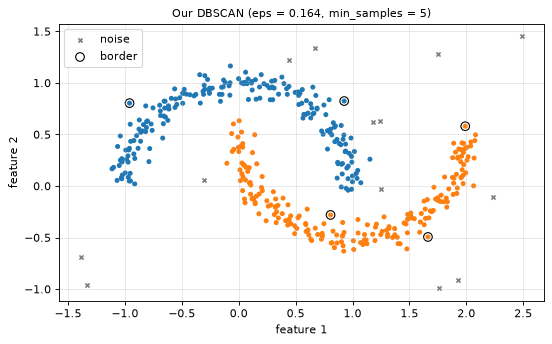

In [2]:
def dbscan(X, eps, min_samples):
    """DBSCAN. Returns (labels with -1 = noise, boolean core-point mask).

    1. Neighbourhood of a point = all points within distance eps, INCLUDING the point itself.
    2. Core point = neighbourhood holds at least `min_samples` points.
    3. Go through the points in order; every unlabelled core point starts a new cluster, which grows outwards
       (breadth-first) through core points. Non-core points reached on the way join as border points but don't
       spread the cluster further. Points never reached stay noise."""
    D = exact_distances(X)
    neighbours = [np.flatnonzero(D[i] <= eps) for i in range(len(X))]     # step 1
    core = np.array([len(nb) >= min_samples for nb in neighbours])        # step 2
    labels = np.full(len(X), -1)                                           # everyone starts as noise
    cluster = 0
    for i in range(len(X)):                                                # step 3
        if labels[i] != -1 or not core[i]:
            continue                                                       # already clustered, or not a seed
        labels[i] = cluster
        queue = deque([i])
        while queue:
            p = queue.popleft()
            if not core[p]:
                continue                                                   # border point: belongs, doesn't spread
            for q in neighbours[p]:
                if labels[q] == -1:                                        # unclaimed (noise so far) -> claim it
                    labels[q] = cluster
                    queue.append(q)
        cluster += 1
    return labels, core


X_db, _ = make_moons(400, noise=0.07, random_state=SEED)
X_db = np.vstack([X_db, np.random.default_rng(SEED).uniform([-1.5, -1], [2.5, 1.5], size=(20, 2))])   # + 20 strays
labels_db, core_db = dbscan(X_db, eps=0.164, min_samples=5)
reference = DBSCAN(eps=0.164, min_samples=5).fit(X_db)
print(f"ours        : {labels_db.max() + 1} clusters, {core_db.sum()} core, {(labels_db == -1).sum()} noise")
print(f"scikit-learn: {reference.labels_.max() + 1} clusters, {len(reference.core_sample_indices_)} core, "
      f"{(reference.labels_ == -1).sum()} noise")
print("identical labels:", np.array_equal(labels_db, reference.labels_),
      "| identical core points:", np.array_equal(np.flatnonzero(core_db), reference.core_sample_indices_))
assert np.array_equal(labels_db, reference.labels_)

fig, ax = plt.subplots(figsize=(7, 4.4))
plot_clusters(ax, X_db, labels_db, "Our DBSCAN (eps = 0.164, min_samples = 5)")
ax.scatter(*X_db[(labels_db != -1) & ~core_db].T, s=60, facecolors="none", edgecolors="k", label="border")
ax.legend(); plt.tight_layout(); plt.show()

> **How to read this**
> * Ours and scikit-learn's agree exactly: **2** clusters, **402** core points, **13** noise points, the same label for
>   every point and the same list of core points.
> * The circled points are border points: inside a cluster, but not dense enough to extend it.

> **Implementation hurdle — a border point next to two clusters.** A border point can lie within `eps` of core points
> from **two** different clusters. It still gets only one label: that of whichever cluster reaches it first. The
> original notes said "assign it to the nearest core point's cluster", which is a sensible alternative, but neither
> the original DBSCAN paper nor scikit-learn does that: the result depends on the **order** of the points. Below,
> point 4 sits exactly between two clusters.

In [3]:
# A border point within eps of core points from TWO clusters: it can only get one label
X_border = np.array([[0.0, 0], [0.3, 0], [0.6, 0], [0.9, 0],     # left cluster (points 0-3, all core)
                     [1.8, 0],                                  # point 4: only 3 neighbours, so a border point
                     [2.7, 0], [3.0, 0], [3.3, 0], [3.6, 0]])   # right cluster (points 5-8, all core)
EPS, MIN_SAMPLES = 0.95, 4
labels_fwd, core_b = dbscan(X_border, EPS, MIN_SAMPLES)
print("core points:", np.flatnonzero(core_b), "| point 4 is core?", core_b[4])
print("points in the original order :", labels_fwd, "-> point 4 joined the",
      "left" if labels_fwd[4] == labels_fwd[0] else "right", "cluster")
reverse = np.arange(len(X_border))[::-1]                         # the same points, listed right to left
labels_rev_listed, _ = dbscan(X_border[reverse], EPS, MIN_SAMPLES)
labels_rev = np.empty(len(X_border), dtype=int); labels_rev[reverse] = labels_rev_listed   # back to original order
print("points in the reversed order:", labels_rev, "-> point 4 joined the",
      "left" if labels_rev[4] == labels_rev[0] else "right", "cluster")
print("scikit-learn, original order :", DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X_border))

core points: [0 1 2 3 5 6 7 8] | point 4 is core? False
points in the original order : [0 0 0 0 0 1 1 1 1] -> point 4 joined the left cluster
points in the reversed order: [1 1 1 1 0 0 0 0 0] -> point 4 joined the right cluster
scikit-learn, original order : [0 0 0 0 0 1 1 1 1]


> **How to read this**
> * Point 4 has only 3 points in its neighbourhood (itself and one point from each side), so with `min_samples` = 4 it
>   is not a core point, while all the others are.
> * Points listed left to right: the left cluster is built first and claims point 4. The same points listed right to
>   left: the right cluster claims it.
> * scikit-learn gives the same answer as ours in the original order. Core points and noise never depend on the order;
>   only border points can.

---

<a id="summary"></a>

## Summary

| Section | Our implementation | Matches the library? | Hurdle shown |
|---|---|---|---|
| [DBSCAN](#sec-4) | DBSCAN | ✔ identical labels and core points | border point between two clusters depends on order |